In [8]:
import numpy as np

def Gauss_Seidel(A, b, max_blap, esl):
    n = len(b)
    x = np.zeros(n)

    # Tính và làm tròn q đến 6 chữ số sau dấu phẩy
    q_values = []
    for i in range(n):
        sigma = np.sum(np.abs(A[i, :])) - np.abs(A[i, i])
        q = round(sigma / np.abs(A[i, i]), 6)
        q_values.append(q)
        print(f"q{i + 1} = {q:.6f}")

    t = max(q_values)
    print(f"Giá trị q lớn nhất: {t:.6f}")

    # Kiểm tra hội tụ bằng q đã làm tròn
    htu = t < 1
    print("Điều kiện hội tụ:", htu)
    if not htu:
        print("Không thỏa điều kiện hội tụ q < 1. Dừng thuật toán.")
        return None

    print()

    for k in range(max_blap):
        x_old = np.copy(x)

        for i in range(n):
            sum1 = np.dot(A[i, :i], x[:i])
            sum2 = np.dot(A[i, i + 1:], x_old[i + 1:])
            x[i] = (b[i] - sum1 - sum2) / A[i, i]

        # Tính sai số bằng q lớn nhất đã làm tròn
        saiso = np.abs(t / (t - 1)) * np.max(np.abs(x - x_old))
        ketqua = np.array2string(
            x,
            formatter={'float_kind': lambda value: f'{value:.6f}'}
        )
        print(f"KQ lần lặp thứ {k + 1}: {ketqua}\n Sai số: {saiso:.6f}")

    return x


In [9]:
def Jacobi(A, b, max_blap, esl):
    n = len(b)
    x = np.zeros(n)

    # Tính và làm tròn q đến 6 chữ số sau dấu phẩy
    q_values = []
    for i in range(n):
        sigma = np.sum(np.abs(A[i, :])) - np.abs(A[i, i])
        q = round(sigma / np.abs(A[i, i]), 6)
        q_values.append(q)
        print(f"q{i + 1} = {q:.6f}")

    t = max(q_values)
    print(f"Giá trị q lớn nhất: {t:.6f}")

    # Kiểm tra hội tụ bằng q đã làm tròn
    htu = t < 1
    print("Điều kiện hội tụ:", htu)
    if not htu:
        print("Không thỏa điều kiện hội tụ q < 1. Dừng thuật toán.")
        return None

    print()

    for k in range(max_blap):
        x_old = np.copy(x)

        for i in range(n):
            sum1 = np.dot(A[i, :i], x_old[:i])
            sum2 = np.dot(A[i, i + 1:], x_old[i + 1:])
            x[i] = (b[i] - sum1 - sum2) / A[i, i]

        # Tính sai số bằng q lớn nhất đã làm tròn
        saiso = np.abs((t / (t - 1)) * np.max(np.abs(x - x_old)))
        ketqua = np.array2string(
            x,
            formatter={'float_kind': lambda value: f'{value:.6f}'}
        )
        print(f"KQ lần lặp thứ {k + 1}: {ketqua}\n Sai số: {saiso:.6f}")

    return x

In [ ]:
def dinh_thuc(M, tol=1e-12): 
   
    M = np.array(M, dtype=float)  # tạo bản sao để không làm thay đổi ma trận gốc

    if M.ndim != 2 or M.shape[0] != M.shape[1]: # kiểm tra: ma trận là ma trận vuông nếu M là mảng 2 chiều và M có số hàng bằng số cột 
        raise ValueError("Định thức chỉ tính cho ma trận vuông.") 

    # khởi tạo
    n = M.shape[0]
    det = 1.0
    #chuyển ma trận M thành ma trận tam giác trên
    #-> det(M) = tích của các phần tử thuộc đường chéo chính
    
    for i in range(n):
        # Chọn phần tử chính (phần tử có giá trị max) theo cột
        p = i + np.argmax(np.abs(M[i:, i]))
        
        # nếu phần tử trụ quá nhỏ -> trụ xấp xỉ 0 -> suy biến
        if abs(M[p, i]) < tol:
            return 0.0

        # Đổi dòng thì định thức đổi dấu
        if p != i:
            M[[i, p]] = M[[p, i]]
            det = -det

        # tích các phần tử trụ (phần tử thuộc đường chéo chính)
        det *= M[i, i]

        # Khử các phần tử phía dưới phần tử chính (khử gauss)
        for j in range(i + 1, n):
            he_so = M[j, i] / M[i, i]
            M[j, i:] -= he_so * M[i, i:]

    return det


def conjugate_gradient(A, b, x0, eps) -> tuple[np.ndarray, int]:
    """
    A: Ma trận vuông, đối xứng xác định dương.
    b: Vectơ vế phải.
    x0: Vectơ nghiệm ban đầu.
    eps: Sai số cho phép, eps > 0.
    """

    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    x = np.asarray(x0, dtype=float).copy()

    # Kiểm tra ma trận vuông
    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A phải là ma trận vuông không rỗng.")

    # lưu cấp của A vào n
    n = A.shape[0]

    # Kiểm tra ma trận đối xứng
    if not np.allclose(A, A.T): # so sánh bằng giữ A vs A^T
        raise ValueError("A phải là ma trận đối xứng.")

    # Kiểm tra xác định dương 
    for k in range(1, n + 1):
        det_k = dinh_thuc(A[:k, :k]) # tính định thức con lấy ra từ k hàng và cột của A
        if det_k <= 0:
            raise ValueError("A không phải ma trận xác định dương ")

    # Khởi tạo phần dư (r) và hướng tìm kiếm (s)
    r = b - np.dot(A, x)
    s = r.copy()

    print("Nghiệm ban đầu x0:", x0)
    print("Phần dư ban đầu r0:", r)

    # kiểm tra nghiệm ban đầu 
    if np.sqrt(np.dot(r, r)) < eps:
        print("Nghiệm ban đầu đã thỏa mãn điều kiện dừng.")
        return x, 0

    # vòng lặp
    for k in range(1, n + 1):

        # Tính alpha = s.r/s.As
        As = np.dot(A, s)
        mau = np.dot(s, As)
        if mau <= 0: # vì ma trận xác định dương nên mẫu phải dương
            raise ValueError("Mẫu số không hợp lệ.")

        alpha = np.dot(s, r) / mau

        # Cập nhật nghiệm, phần dư và chuẩn phần dư để xét điều kiện dừng
        x = x + alpha * s
        r_moi = b - np.dot(A, x)
        chuan_r = np.sqrt(np.sum(r_moi**2))

        # Hiển thị kết quả từng lần lặp
        print(f"\nLần lặp thứ {k}:")
        print("Nghiệm x =", [round(float(i), 6) for i in x])
        print("Phần dư r =", [round(float(i), 6) for i in r_moi])
        print("Chuẩn phần dư ||r|| =", round(float(chuan_r), 6))

        # Kiểm tra điều kiện dừng
        if chuan_r < eps:b
            print(f"Thỏa mãn sau {k} lần lặp.")
            return x, k
            
        # Tính beta
        beta = -np.dot(r_moi, As) / mau

        # Cập nhật hướng tìm kiếm
        s = r_moi + beta * s
        r = r_moi.copy()
        
    return x, n

Lưới 5x5, số ẩn n = 25, epsilon = 1e-08
Hệ số q theo hàng = 1.000000 (q = 1 không có nghĩa là phân kỳ)
Bán kính phổ Jacobi:       rho(B_J)  = 0.866025
Bán kính phổ Gauss-Seidel: rho(B_GS) = 0.750000

Phương pháp              Bước lặp        Sai số cuối       Đạt eps?
Jacobi                        154          9.323e-09           True
Gauss-Seidel                   77          7.575e-09           True
Gradient liên hợp              11          1.421e-14           True

Kiểm chứng CG: 11 <= n = 25: True


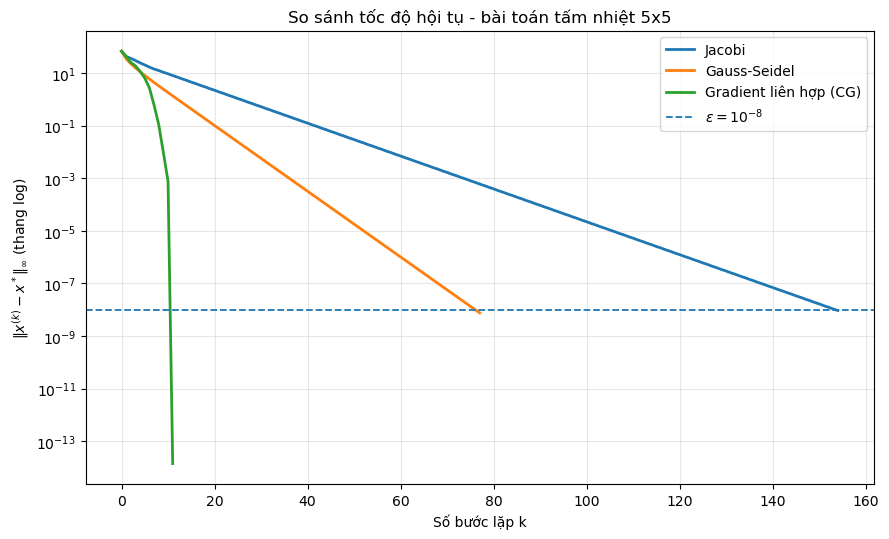

In [11]:
import matplotlib.pyplot as plt

EPS = 1e-8
MAX_LAP = 10000
m = 5  # Lưới 5 x 5 => n = 25 ẩn


def tao_he_tam_nhiet(m):
    """Biên trên 100 độ, ba biên còn lại 0 độ."""
    n = m * m
    A = np.zeros((n, n), dtype=float)
    b = np.zeros(n, dtype=float)

    for i in range(m):
        for j in range(m):
            k = i * m + j
            A[k, k] = 4
            if i > 0:
                A[k, (i - 1) * m + j] = -1
            if i < m - 1:
                A[k, (i + 1) * m + j] = -1
            if j > 0:
                A[k, i * m + (j - 1)] = -1
            if j < m - 1:
                A[k, i * m + (j + 1)] = -1
            if i == 0:
                b[k] += 100
    return A, b


def chay_jacobi_luu_sai_so(A, b, x_sao, eps, max_lap):
    """Vẫn dùng công thức Jacobi ở cell 2; lưu sai số thật sau mỗi bước."""
    n = len(b)
    x = np.zeros(n)
    lich_su = [np.max(np.abs(x - x_sao))]  # k = 0
    for k in range(1, max_lap + 1):
        x_cu = x.copy()
        for i in range(n):
            tong_trai = np.dot(A[i, :i], x_cu[:i])
            tong_phai = np.dot(A[i, i + 1:], x_cu[i + 1:])
            x[i] = (b[i] - tong_trai - tong_phai) / A[i, i]
        sai_so = np.max(np.abs(x - x_sao))
        lich_su.append(sai_so)
        if sai_so < eps:
            break
    return x, np.array(lich_su)


def chay_gs_luu_sai_so(A, b, x_sao, eps, max_lap):
    """Vẫn dùng công thức GS ở cell 1; lưu sai số thật sau mỗi bước."""
    n = len(b)
    x = np.zeros(n)
    lich_su = [np.max(np.abs(x - x_sao))]  # k = 0
    for k in range(1, max_lap + 1):
        x_cu = x.copy()
        for i in range(n):
            tong_trai = np.dot(A[i, :i], x[:i])
            tong_phai = np.dot(A[i, i + 1:], x_cu[i + 1:])
            x[i] = (b[i] - tong_trai - tong_phai) / A[i, i]
        sai_so = np.max(np.abs(x - x_sao))
        lich_su.append(sai_so)
        if sai_so < eps:
            break
    return x, np.array(lich_su)


def chay_cg_luu_sai_so(A, b, x_sao, eps):
    """Vẫn dùng cách tính alpha, beta và hướng s của cell 3."""
    n = len(b)
    x = np.zeros(n)
    r = b - A @ x
    s = r.copy()
    lich_su = [np.max(np.abs(x - x_sao))]  # k = 0
    for k in range(1, n + 1):
        As = A @ s
        mau = s @ As
        if mau <= 0:
            raise ValueError("Mẫu số trong CG không dương.")
        alpha = (s @ r) / mau
        x = x + alpha * s
        r_moi = b - A @ x
        sai_so = np.max(np.abs(x - x_sao))
        lich_su.append(sai_so)
        if sai_so < eps:
            break
        beta = -(r_moi @ As) / mau
        s = r_moi + beta * s
        r = r_moi.copy()
    return x, np.array(lich_su)


# 1. Tạo hệ Ax = b và nghiệm tham chiếu x*
A, b = tao_he_tam_nhiet(m)
n = len(b)
x_sao = np.linalg.solve(A, b)

# 2. Thực nghiệm ba phương pháp, dừng khi ||x(k)-x*||_inf < 1e-8
x_j, e_j = chay_jacobi_luu_sai_so(A, b, x_sao, EPS, MAX_LAP)
x_gs, e_gs = chay_gs_luu_sai_so(A, b, x_sao, EPS, MAX_LAP)
x_cg, e_cg = chay_cg_luu_sai_so(A, b, x_sao, EPS)

# 3. Ma trận lặp và bán kính phổ (dùng np.linalg.solve, tránh lấy nghịch đảo trực tiếp)
D = np.diag(np.diag(A))
L = np.tril(A, k=-1)
U = np.triu(A, k=1)
B_J = -np.linalg.solve(D, L + U)
B_GS = -np.linalg.solve(D + L, U)
rho_J = np.max(np.abs(np.linalg.eigvals(B_J)))
rho_GS = np.max(np.abs(np.linalg.eigvals(B_GS)))
q = np.max((np.sum(np.abs(A), axis=1) - np.abs(np.diag(A))) / np.abs(np.diag(A)))

print(f"Lưới {m}x{m}, số ẩn n = {n}, epsilon = {EPS:.0e}")
print(f"Hệ số q theo hàng = {q:.6f} (q = 1 không có nghĩa là phân kỳ)")
print(f"Bán kính phổ Jacobi:       rho(B_J)  = {rho_J:.6f}")
print(f"Bán kính phổ Gauss-Seidel: rho(B_GS) = {rho_GS:.6f}")
print("\n{:<22} {:>10} {:>18} {:>14}".format("Phương pháp", "Bước lặp", "Sai số cuối", "Đạt eps?"))
for ten, e in [("Jacobi", e_j), ("Gauss-Seidel", e_gs), ("Gradient liên hợp", e_cg)]:
    print("{:<22} {:>10} {:>18.3e} {:>14}".format(ten, len(e) - 1, e[-1], str(e[-1] < EPS)))
print(f"\nKiểm chứng CG: {len(e_cg)-1} <= n = {n}: {len(e_cg)-1 <= n}")

# 4. Vẽ sai số thật theo k, trục tung là logarithm
plt.figure(figsize=(9, 5.5))
for ten, e in [("Jacobi", e_j), ("Gauss-Seidel", e_gs), ("Gradient liên hợp (CG)", e_cg)]:
    plt.semilogy(np.arange(len(e)), np.maximum(e, np.finfo(float).tiny),
                 linewidth=2, label=ten)
plt.axhline(EPS, linestyle="--", linewidth=1.3, label=r"$\varepsilon=10^{-8}$")
plt.xlabel("Số bước lặp k")
plt.ylabel(r"$\|x^{(k)}-x^*\|_\infty$ (thang log)")
plt.title(f"So sánh tốc độ hội tụ - bài toán tấm nhiệt {m}x{m}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("so_sanh_hoi_tu.png", dpi=180)
plt.show()


## Nhận xét thực nghiệm (lưới $5 \times 5$)

### 1. Điều kiện dừng

Thực nghiệm sử dụng điều kiện dừng:

$$
\|x^{(k)}-x^*\|_\infty < 10^{-8}
$$

Trong đó, $x^* = \operatorname{solve}(A,b)$ là nghiệm tham chiếu được tính bằng NumPy.

Điều kiện này khác với tiêu chuẩn dừng dựa trên chuẩn phần dư của thuật toán Gradient liên hợp ban đầu.

### 2. So sánh số bước lặp

| Phương pháp | Số bước lặp | Sai số cuối |
|---|---:|---:|
| Jacobi | 154 | $9.323 \times 10^{-9}$ |
| Gauss–Seidel | 77 | $7.575 \times 10^{-9}$ |
| Gradient liên hợp | 11 | $1.421 \times 10^{-14}$ |

**Nhận xét:** Gradient liên hợp hội tụ nhanh nhất, tiếp theo là Gauss–Seidel và cuối cùng là Jacobi.

### 3. Kiểm chứng tính hội tụ của Gradient liên hợp

Với lưới $5 \times 5$, hệ phương trình có $n=25$ ẩn.

Gradient liên hợp hội tụ sau 11 bước lặp, thỏa mãn:

$$
11 \leq 25 = n
$$

Kết quả phù hợp với tính chất lý thuyết: Gradient liên hợp hội tụ trong không quá $n$ bước đối với ma trận đối xứng xác định dương khi tính toán chính xác.

Trong thực tế, sai số làm tròn có thể ảnh hưởng đến tính chất này.

### 4. Mối liên hệ giữa tốc độ hội tụ và bán kính phổ

Bán kính phổ của hai ma trận lặp:

$$
\rho(B_J) \approx 0.866025
$$

$$
\rho(B_{GS}) \approx 0.750000
$$

Ta có:

$$
\rho(B_{GS}) < \rho(B_J) < 1
$$

**Nhận xét:** Bán kính phổ của Gauss–Seidel nhỏ hơn Jacobi, cho thấy tốc độ hội tụ tiệm cận của Gauss–Seidel nhanh hơn.

Kết quả thực nghiệm phù hợp với nhận xét này khi Gauss–Seidel chỉ cần 77 bước lặp, trong khi Jacobi cần 154 bước lặp.

### 5. Nhận xét về điều kiện hội tụ

Đối với ma trận của bài toán phân bố nhiệt trên tấm phẳng, hệ số $q=1$ do một số hàng có bốn phần tử ngoài đường chéo bằng $-1$, trong khi phần tử đường chéo chính bằng $4$.

Vì vậy, điều kiện đủ:

$$
q<1
$$

không được thỏa mãn. Tuy nhiên, điều này không có nghĩa là phương pháp phân kỳ.

Do:

$$
\rho(B_J)<1,\qquad \rho(B_{GS})<1
$$

nên cả Jacobi và Gauss–Seidel đều hội tụ.

### 6. Kết luận

Qua thực nghiệm, cả ba phương pháp đều đạt độ chính xác yêu cầu.

- **Gradient liên hợp:** Có số bước lặp ít nhất và hội tụ sau không quá $n$ bước trong thực nghiệm.
- **Gauss–Seidel:** Hội tụ nhanh hơn Jacobi, phù hợp với bán kính phổ nhỏ hơn.
- **Jacobi:** Hội tụ chậm hơn nhưng vẫn đạt độ chính xác yêu cầu.

Kết quả cho thấy bán kính phổ là tiêu chí quan trọng để đánh giá sự hội tụ và tốc độ hội tụ tiệm cận của các phương pháp lặp.

**Lưu ý:** Trong thực nghiệm, các công thức lặp được giữ nguyên theo ba thuật toán ban đầu, đồng thời bổ sung việc lưu lịch sử sai số để phục vụ so sánh và vẽ đồ thị.
